| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../7_METODOS_NUMERICOS_PARA_ODE/7_3_Midpoint.ipynb) | [⏩](../7_METODOS_NUMERICOS_PARA_ODE/7_5_Metodos_adaptativos.ipynb) |

# 7.4 Runge–Kutta: construir alta precisión con varias pendientes

Los métodos Runge–Kutta combinan evaluaciones internas de la dinámica. Estudiaremos RK4 clásico, su tabla de Butcher, convergencia de orden cuatro, estabilidad y errores de energía y fase. Compararemos una implementación educativa de paso fijo con `solve_ivp`, cuya variante RK45 es adaptativa y distinta de RK4.

Los experimentos son autocontenidos y rápidos en CPU. Requisitos: derivadas, integrales, ecuaciones diferenciales ordinarias y errores numéricos. Ejecuta todas las celdas en orden. La solución exacta se usa como control cuando está disponible; en otros casos se compara contra una solución de referencia más precisa.

## 1. Problema de valor inicial y notación

Un problema de valor inicial tiene forma
$$y'(t)=f(t,y(t)),\qquad y(t_0)=y_0.$$
El estado $y$ puede ser un número o un vector. La función $f$ expresa la ley física y sus unidades son unidades de estado por unidades de tiempo. Bajo continuidad en $t$ y una condición local de Lipschitz en $y$, existe una solución única local; una implementación numérica no reemplaza estos supuestos.

Usaremos una malla $t_n=t_0+nh$ y una aproximación $y_n\approx y(t_n)$. Es esencial distinguir una evaluación de pendiente $f(t_n,y_n)$ de una actualización del estado. Para enfriamiento $y'=-ky$, el coeficiente $k>0$ tiene unidades de inverso del tiempo y la solución exacta es $y_0e^{-kt}$.

Un simulador introduce error de discretización además del error del modelo. Si una red se entrena con sus trayectorias, puede aprender ambas cosas. Por ello se estudian refinamiento, estabilidad y coste antes de usar los resultados como datos científicos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar
plt.rcParams.update({"figure.figsize":(9,4), "axes.grid":True, "font.size":11})
np.set_printoptions(precision=6,suppress=True)

## 2. Los cuatro estadios de RK4

RK4 clásico utiliza
$$k_1=f(t_n,y_n),\quad k_2=f(t_n+h/2,y_n+hk_1/2),$$
$$k_3=f(t_n+h/2,y_n+hk_2/2),\quad k_4=f(t_n+h,y_n+hk_3),$$
$$\boxed{y_{n+1}=y_n+\frac h6(k_1+2k_2+2k_3+k_4)}.$$
Los $k_i$ son pendientes, no incrementos: cada uno conserva unidades de estado/tiempo. Algunas implementaciones incorporan $h$ en cada $k_i$ y entonces la fórmula final cambia; mezclar ambas convenciones multiplica dos veces por el paso.

El coste básico es cuatro evaluaciones por paso. Los estadios dos y tres ocurren al mismo tiempo pero en estados predichos diferentes.

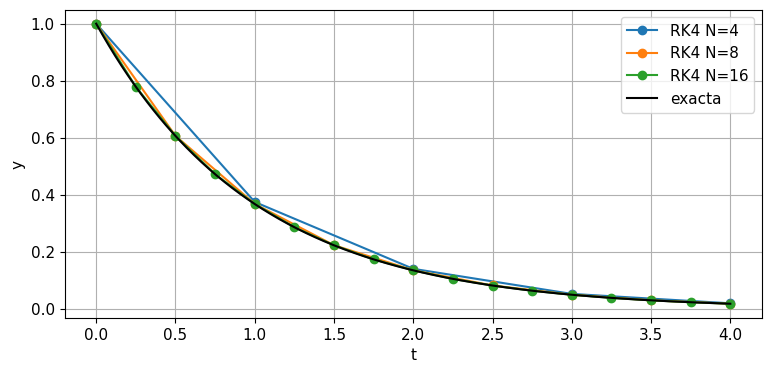

In [2]:
def rk4(fun,tspan,y0,n):
    t=np.linspace(*tspan,n+1); h=t[1]-t[0]
    y=np.empty((n+1,np.atleast_1d(y0).size)); y[0]=np.atleast_1d(y0)
    for j in range(n):
        k1=np.asarray(fun(t[j],y[j]))
        k2=np.asarray(fun(t[j]+h/2,y[j]+h*k1/2))
        k3=np.asarray(fun(t[j]+h/2,y[j]+h*k2/2))
        k4=np.asarray(fun(t[j]+h,y[j]+h*k3))
        y[j+1]=y[j]+h*(k1+2*k2+2*k3+k4)/6
    return t,y

q=np.linspace(0,4,500)
for n in [4,8,16]:
    t,y=rk4(lambda t,y:-y,(0,4),1.,n)
    plt.plot(t,y[:,0],"o-",label=f"RK4 N={n}")
plt.plot(q,np.exp(-q),"k",label="exacta")
plt.xlabel("t"); plt.ylabel("y"); plt.legend(); plt.show()

**Interpretación.** Con pasos moderados, RK4 puede acercarse mucho más que métodos de orden bajo. Eso no implica estabilidad para pasos arbitrariamente grandes; cuatro pendientes no reemplazan las restricciones del problema.

## 3. Tabla de Butcher y condiciones de orden

La tabla se resume en abscisas $c=(0,1/2,1/2,1)$, coeficientes $A_{21}=1/2$, $A_{32}=1/2$, $A_{43}=1$ y pesos $b=(1/6,1/3,1/3,1/6)$. Todos los demás $A_{ij}$ son cero: cada estadio depende solo de anteriores, por lo que es explícito.

Los pesos suman uno. Además $\sum b_i c_i=1/2$, $\sum b_i c_i^2=1/3$ y $\sum b_i c_i^3=1/4$, condiciones necesarias relacionadas con integrar potencias temporales. Para ecuaciones no lineales existen condiciones adicionales sobre combinaciones de $A$ y $b$; no basta escoger una cuadratura de cuarto orden y asumir que cualquier predictor tendrá ese orden.

RK4 satisface las condiciones completas de cuarto orden. El defecto de un paso es $O(h^5)$ y el error global $O(h^4)$ bajo suavidad y estabilidad.

In [3]:
b=np.array([1/6,1/3,1/3,1/6]); abscissas=np.array([0.,0.5,0.5,1.])
for power in range(4):
    print("momento",power,":",b@abscissas**power,"esperado:",1/(power+1))

momento 0 : 0.9999999999999999 esperado: 1.0
momento 1 : 0.5 esperado: 0.5
momento 2 : 0.3333333333333333 esperado: 0.3333333333333333
momento 3 : 0.25 esperado: 0.25


**Interpretación.** Los momentos correctos verifican parte de las condiciones de orden. Esta comprobación no constituye una demostración completa para campos no lineales, pero ayuda a interpretar los pesos.

## 4. Convergencia de cuarto orden

Medimos $E=|y_N-e^{-T}|$ para $T=4$. Al dividir el paso por dos, la reducción asintótica debe aproximarse a $2^4=16$. El experimento usa pasos suficientemente pequeños para precisión, pero no tan pequeños que el error de redondeo domine.

Órdenes: [4.305051 4.151043 4.075313 4.037612]


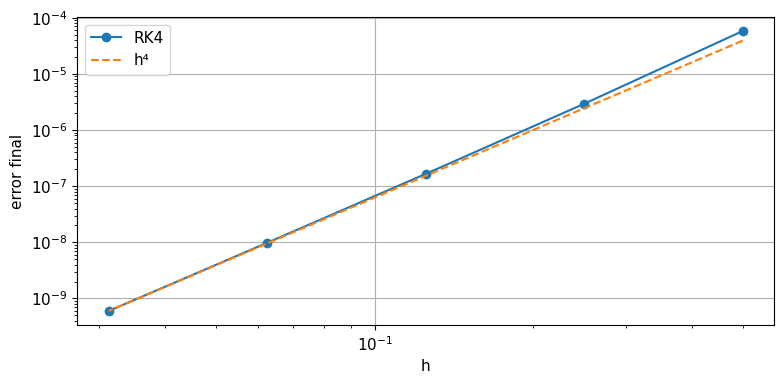

In [4]:
ns=np.array([8,16,32,64,128]); errors=[]
for n in ns:
    _,y=rk4(lambda t,y:-y,(0,4),1.,n)
    errors.append(abs(y[-1,0]-np.exp(-4)))
errors=np.array(errors)
print("Órdenes:",np.log2(errors[:-1]/errors[1:]))
plt.loglog(4/ns,errors,"o-",label="RK4")
plt.loglog(4/ns,errors[-1]*(ns[-1]/ns)**4,"--",label="h⁴")
plt.xlabel("h"); plt.ylabel("error final"); plt.legend(); plt.show()

**Interpretación.** Las tasas deben acercarse a cuatro al refinar. Si comparas con una referencia aproximada, su error debe estar bastante por debajo de los valores medidos, especialmente para métodos de alto orden.

## 5. Estabilidad absoluta

Para $y'=\lambda y$,
$$R(z)=1+z+\frac{z^2}{2}+\frac{z^3}{6}+\frac{z^4}{24}.$$
Es el polinomio de Taylor de $e^z$ hasta grado cuatro. La región $|R(z)|\le1$ es acotada: RK4 no es A-estable. Sobre el eje real negativo llega aproximadamente hasta $z=-2.785$, y sobre el imaginario incluye $|\operatorname{Im}z|\le\sqrt8$.

Una ecuación con $\lambda=-1000$ necesita $h$ de escala $10^{-3}$ por estabilidad, aunque su solución visible cambie despacio después de un transitorio. Un método explícito de mayor orden no elimina automáticamente rigidez.

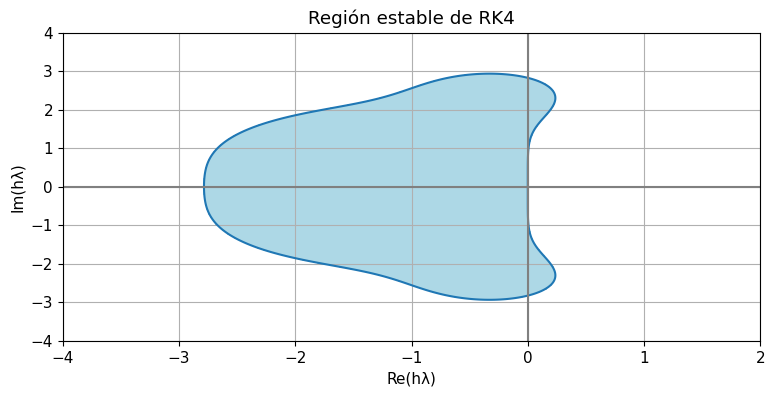

In [5]:
re=np.linspace(-4,2,400); im=np.linspace(-4,4,400)
Z=re[None,:]+1j*im[:,None]
R=1+Z+Z**2/2+Z**3/6+Z**4/24
plt.contourf(re,im,abs(R)<=1,levels=[-0.5,0.5,1.5],colors=["white","lightblue"])
plt.contour(re,im,abs(R),levels=[1],colors="tab:blue")
plt.axhline(0,color="gray"); plt.axvline(0,color="gray")
plt.xlabel("Re(hλ)"); plt.ylabel("Im(hλ)"); plt.title("Región estable de RK4")
plt.show()

**Interpretación.** La región se extiende más que la de Euler o Heun, pero sigue limitada. Coloca mentalmente los autovalores del problema multiplicados por el paso para evaluar si esta mejora es suficiente.

## 6. Oscilador: energía y fase

Para $q'=p$, $p'=-q$, los autovalores son $\pm i$. Un paso RK4 pequeño suele amortiguar muy ligeramente la energía en lugar de hacerla crecer como Euler. Tampoco conserva exactamente la estructura Hamiltoniana.

La energía y el error de fase son observables complementarios. Un método puede producir amplitud correcta y desfase creciente, o un desfase pequeño con amplitud errónea. En simulaciones largas es necesario medir ambos.

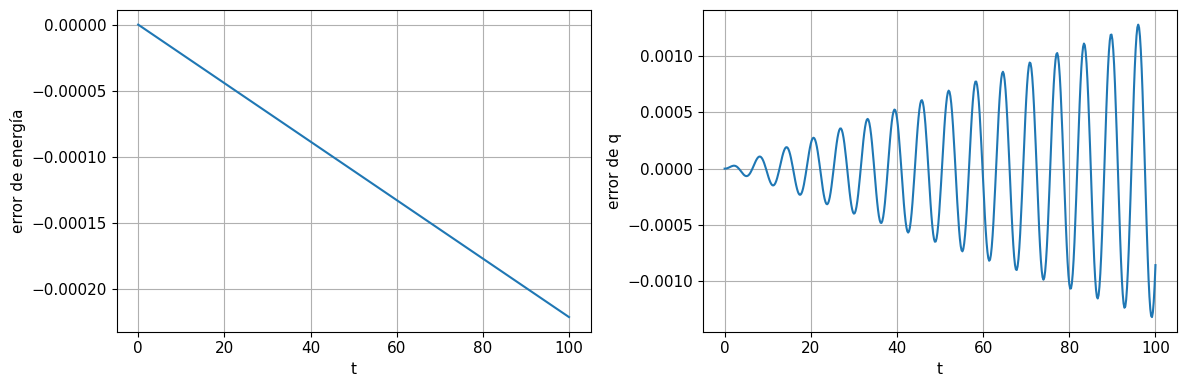

In [6]:
t,y=rk4(lambda t,y:np.array([y[1],-y[0]]),(0,100),[1.,0.],500)
energy=0.5*np.sum(y*y,axis=1)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(t,energy-0.5); ax[0].set(xlabel="t",ylabel="error de energía")
ax[1].plot(t,y[:,0]-np.cos(t)); ax[1].set(xlabel="t",ylabel="error de q")
plt.tight_layout(); plt.show()

**Interpretación.** Aunque ambos errores sean pequeños, muestran acumulación temporal. Para comparar distintos pasos usa el mismo tiempo final; cambiar el horizonte altera la dificultad del experimento.

## 7. Un sistema no lineal: péndulo

El péndulo sin amortiguamiento satisface $\theta'=\omega$, $\omega'=-(g/\ell)\sin\theta$. Su energía por unidad de masa es $E=\ell^2\omega^2/2+g\ell(1-\cos\theta)$.

La aproximación lineal $\sin\theta\approx\theta$ predice periodo $2\pi\sqrt{\ell/g}$, pero a amplitud grande el periodo aumenta. Usar RK4 no corrige una mala aproximación física: método numérico y modelo son elecciones distintas.

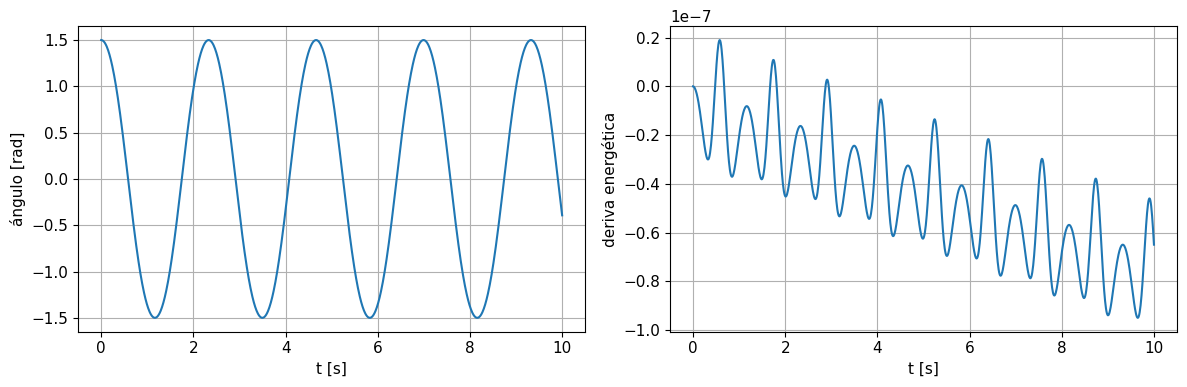

In [7]:
g,length=9.81,1.
def pendulum(t,y): return np.array([y[1],-g/length*np.sin(y[0])])
t,y=rk4(pendulum,(0,10),[1.5,0.],1000)
energy=0.5*length**2*y[:,1]**2+g*length*(1-np.cos(y[:,0]))
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(t,y[:,0]); ax[0].set(xlabel="t [s]",ylabel="ángulo [rad]")
ax[1].plot(t,energy-energy[0]); ax[1].set(xlabel="t [s]",ylabel="deriva energética")
plt.tight_layout(); plt.show()

**Interpretación.** La energía casi se conserva a esta resolución, ofreciendo un diagnóstico del integrador. Para determinar un periodo preciso, localiza cruces con eventos o interpolación adecuada en lugar de leer picos a ojo.

## 8. RK4 frente a RK45 de SciPy

`solve_ivp(...,method="RK45")` utiliza un par embebido Dormand–Prince de órdenes cinco y cuatro con adaptación del paso; no es el RK4 clásico anterior. El solver controla una estimación de error local y entrega estados en los tiempos solicitados mediante interpolación interna.

`t_eval` define tiempos de salida; no fuerza esos mismos pasos de integración. `nfev` cuenta evaluaciones de la función y `success` indica si el solver completó la tarea según sus criterios, no si el modelo físico es verdadero.

Éxito: True nfev: 3026 RK4 nfev: 4000
Discrepancia máxima: 4.080737263656431e-07


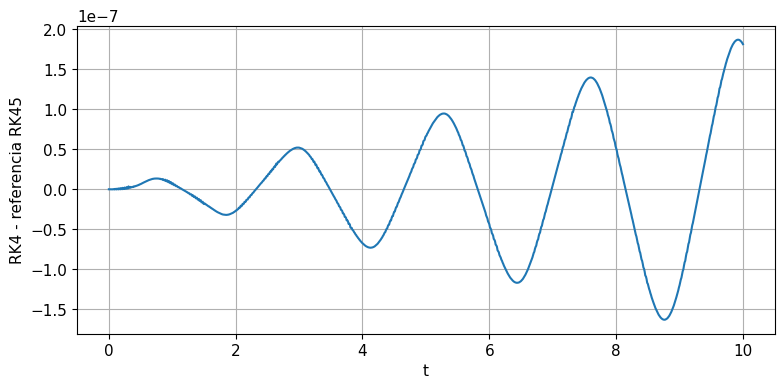

In [8]:
out=solve_ivp(pendulum,(0,10),[1.5,0.],method="RK45",t_eval=t,
              rtol=1e-9,atol=1e-11)
print("Éxito:",out.success,"nfev:",out.nfev,"RK4 nfev:",4*(len(t)-1))
print("Discrepancia máxima:",np.max(abs(y-out.y.T)))
plt.plot(t,y[:,0]-out.y[0]); plt.xlabel("t"); plt.ylabel("RK4 - referencia RK45")
plt.show()

**Interpretación.** La comparación ayuda a estimar error del paso fijo, siempre que la referencia sea más precisa. Para confirmar, estrecha la tolerancia de referencia y comprueba que la diferencia principal permanezca estable.

## 9. Escalas y límites de alto orden

Una función no suave, una discontinuidad de control o una colisión puede reducir el orden observado. Integrar a través del evento como si todo fuese suave mezcla leyes físicas distintas. Divide el problema y reinicia el solver cuando cambie la dinámica.

Escalar tiempo y estado puede facilitar la elección del paso y de tolerancias. Para el péndulo, $\tau=t\sqrt{g/\ell}$ convierte el sistema en $\theta_{\tau\tau}=-\sin\theta$. Esta forma adimensional permite comparar longitudes sin confundir cambios físicos con cambios numéricos.

## 10. Convergencia, error y coste: cómo hacer una comparación justa

Si un método tiene orden global $p=4$, en el régimen asintótico se espera $E(h)\approx C h^p$ para problemas suficientemente suaves y un intervalo temporal fijo. El estimador
$$p_{\rm obs}=\log_2\frac{E(h)}{E(h/2)}$$
solo es significativo mientras el error de referencia y el redondeo sean menores que el error medido. Una trayectoria visualmente correcta puede tener error de fase, sesgo en un observable o errores localizados en transitorios.

Para comparar métodos, cuenta evaluaciones de $f$, resoluciones lineales y, en métodos implícitos, iteraciones de Newton. Un método de más orden puede ser más barato para una precisión dada, pero no necesariamente para una tolerancia muy laxa o una función no suave. Si aparecen discontinuidades o eventos, separa los intervalos suaves y localiza el cambio.

Guarda el tiempo final real de cada integración. Usar `int(T/h)` puede terminar antes de $T$ si el cociente no es entero. En estos ejemplos fijamos el número de pasos y calculamos $h=(T-t_0)/N$ para llegar exactamente al extremo. Una malla de salida fija tampoco debe confundirse con los pasos internos de un solver adaptativo.

## 11. De la simulación a SciML

En un problema inverso se ajusta un parámetro $\theta$ minimizando
$$L_h(\theta)=\sum_i\left[y_h(t_i;\theta)-y_i^{\rm obs}\right]^2.$$
El subíndice $h$ recuerda que estamos optimizando la salida de un simulador discretizado. Si el método RK4 genera un sesgo sistemático, el ajuste puede compensarlo con un parámetro equivocado. Repite la inferencia con una malla más fina y observa si el parámetro estimado cambia.

En una Neural ODE, $f_\theta(t,y)$ puede ser una red, pero el solver conserva sus requisitos de regularidad y estabilidad. Reducir la pérdida de entrenamiento no prueba precisión de integración. Para física diferenciable, una derivada del programa discreto es una sensibilidad de ese programa; hace falta verificar que se estabiliza al refinar la discretización.

Define qué observable importa: valor final, energía, evento, amplitud o una norma de trayectoria. No compares únicamente la apariencia de curvas. Una evaluación científica útil separa error de datos, error de modelo y error numérico, porque mejorar uno de ellos no garantiza mejorar los demás.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../7_METODOS_NUMERICOS_PARA_ODE/7_3_Midpoint.ipynb) | [⏩](../7_METODOS_NUMERICOS_PARA_ODE/7_5_Metodos_adaptativos.ipynb) |